In [1]:
%load_ext autoreload
%autoreload 2

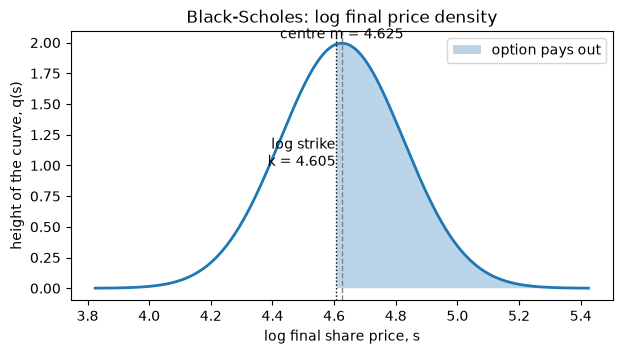

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pricing import centre_and_spread, log_price_density

S0, r, T, vol, K = 100, 0.04, 1.0, 0.20, 100

# 1. Work out where the curve sits, so the plot covers it
m, spread = centre_and_spread(S0, r, T, vol)
s = np.linspace(m - 4 * spread, m + 4 * spread, 500)

# 2. Height of the bell curve at each log price
q = log_price_density(s, S0, r, T, vol)

# 3. Plot it
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(s, q, lw=2)

# 4. Shade the part above the log strike: where the option pays out
k = np.log(K)
ax.fill_between(s, q, where=(s > k), alpha=0.3, label="option pays out")

# 5. Mark the centre and the strike
ax.axvline(m, ls="--", color="grey", lw=1)
ax.axvline(k, ls=":", color="black", lw=1)
ax.text(m, q.max() * 1.02, f"centre m = {m:.3f}", ha="center")
ax.text(k, q.max() * 0.5, f"log strike\nk = {k:.3f}", ha="right")

ax.set_xlabel("log final share price, s")
ax.set_ylabel("height of the curve, q(s)")
ax.set_title("Black-Scholes: log final price density")
ax.legend()
plt.show()

In [3]:
from pricing import price_by_average

price_by_average(100, 100, 0.04, 1.0, 0.20)

np.float64(9.925053717274436)

In [4]:
from pricing import fingerprint_bs
import numpy as np


F = fingerprint_bs(1, 100, 0.04, 1.0, 0.20)
print(abs(F), np.angle(F) % (2 * np.pi))

0.9801986733067553 4.625170185988091


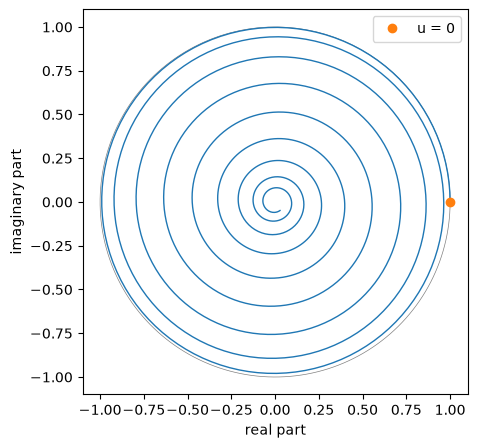

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pricing import fingerprint_bs

u = np.linspace(0, 12, 1000)
F = fingerprint_bs(u, 100, 0.04, 1.0, 0.20)

fig, ax = plt.subplots(figsize=(5, 5))
theta = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(theta), np.sin(theta), color="grey", lw=0.5)  # circle of radius 1
ax.plot(F.real, F.imag, lw=1)                                # path of the arrow's tip
ax.plot(1, 0, "o", label="u = 0")
ax.set_aspect("equal")
ax.set_xlabel("real part")
ax.set_ylabel("imaginary part")
ax.legend()
plt.show()

## outcomes arrows spin around the origin, shrinking as the spin increases, this is the fourier transform of log-price distribution

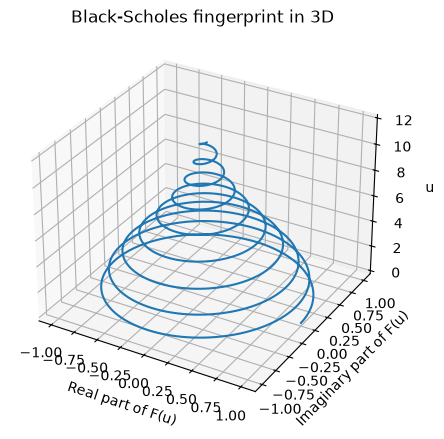

In [6]:
## with u as a third dimension

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")

ax.plot(F.real, F.imag, u, lw=1.5)
ax.set_xlabel("Real part of F(u)")
ax.set_ylabel("Imaginary part of F(u)")
ax.set_zlabel("u")
ax.set_title("Black-Scholes fingerprint in 3D")

plt.show()

In [7]:
from pricing import bs_price, damped_price

for K in [0.0001, 1, 100]:
    print(K, bs_price(100, K, 0.04, 1.0, 0.20), damped_price(100, K, 0.04, 1.0, 0.20))

0.0001 99.99990392105609 9.99999039210561e-05
1 99.03921056084768 99.03921056084768
100 9.925053717274437 9925.053717274437


In [8]:
from pricing import wound_up

wound_up(2.0, 100, 0.04, 1.0, 0.20)

np.complex128(74.94335225999684+13200.101047459502j)